Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC2017 Modelación y Simulación

# 04. Modelo integrado y Monte Carlo

En este notebook se unen las tres capas. Cada mes los agentes generan visitas, la tabla de la cola estima qué fracción se pierde y esa pérdida aumenta el abandono del mes siguiente. Las visitas atendidas entran como demanda al modelo de caja, inventario y deuda.

El futuro es incierto, por lo que se simulan 1 000 escenarios con Monte Carlo. En cada escenario se sortean el nivel del mercado, la fuerza del boca a boca, el abandono, el costo de los insumos, el ticket promedio y un choque mensual en las visitas. El resultado es un rango de escenarios, no una predicción exacta.

## 1. Preparación

Se calcula la tabla de pérdida del notebook 03 con 2 servidores como caso base.

In [1]:
import sys
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../src")
from business_sim.model import simulate_business
from business_sim.montecarlo import run_montecarlo
from business_sim.params import BusinessParams, CustomerParams, QueueParams
from business_sim.queue_des import loss_table

p, cp, qp = BusinessParams(), CustomerParams(), QueueParams()
tabla = loss_table(qp, list(range(0, 201, 10)), [1, 2, 3, 4], days=60, seed=5)
N = 1000
meses = np.arange(1, p.horizon + 1)

## 2. Una corrida integrada

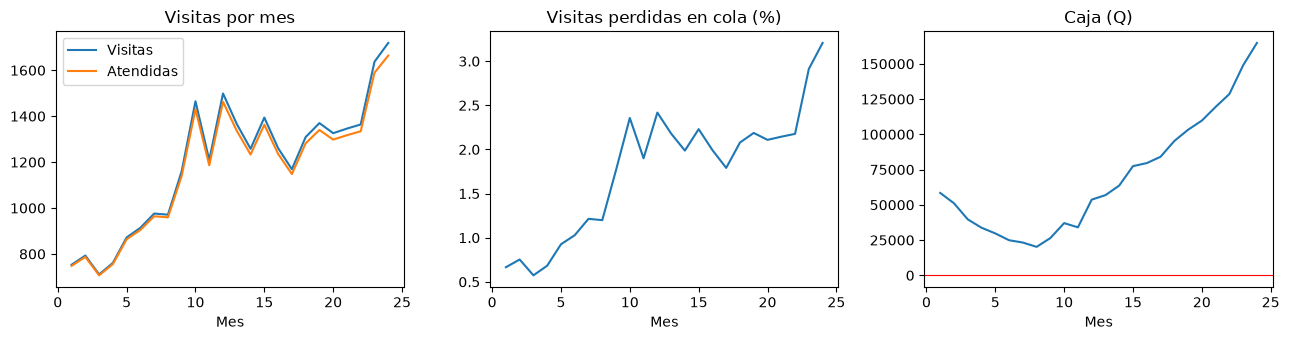

Caja mínima = Q20,185 en el mes 8


,active,visits,loss,queue_served,revenue,cash
month,,,,,,
1,340,753,0.007,747.987,33659.436,58444.196
6,478,914,0.010,904.598,40706.896,24882.972
12,633,1499,0.024,1462.757,64045.668,53684.139
24,751,1719,0.032,1663.874,74874.319,164810.936


In [2]:
una = simulate_business(p, cp, qp, tabla, rng=1, noise=0.05)

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.5))
ejes[0].plot(meses, una["visits"], label="Visitas")
ejes[0].plot(meses, una["queue_served"], label="Atendidas")
ejes[0].set_title("Visitas por mes")
ejes[0].legend()
ejes[1].plot(meses, una["loss"] * 100)
ejes[1].set_title("Visitas perdidas en cola (%)")
ejes[2].plot(meses, una["cash"])
ejes[2].axhline(0, color="red", lw=0.8)
ejes[2].set_title("Caja (Q)")
for eje in ejes:
    eje.set_xlabel("Mes")
plt.tight_layout()
plt.show()
print(f"Caja mínima = Q{una['cash'].min():,.0f} en el mes {una['cash'].idxmin()}")
una.loc[[1, 6, 12, 24], ["active", "visits", "loss", "queue_served", "revenue", "cash"]].round(3)

En esta corrida la pérdida en cola sube de 0.7 % en el mes 1 a 3.2 % en el mes 24, a medida que crecen las visitas. La caja baja hasta Q20 185 en el mes 8 y cierra el mes 24 con Q164 811.

## 3. Monte Carlo con la demanda esperada

El escenario peor corresponde al percentil 10, el probable a la mediana y el mejor al percentil 90.

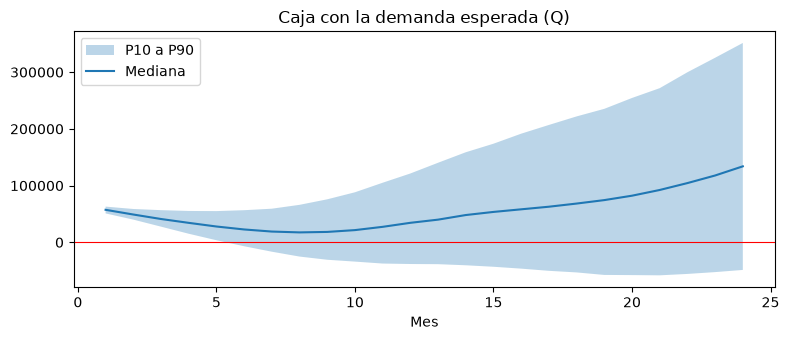

Probabilidad de quedarse sin caja en 24 meses = 0.350
Pérdida media en cola = 1.776%


,Meses que aguanta,Caja mínima (Q),Caja final (Q)
Peor (P10),5.0,-59292.0,-48653.0
Probable (P50),24.0,15822.0,133954.0
Mejor (P90),24.0,52870.0,351415.0


In [3]:
def abanico(caja, titulo, eje):
    """Dibuja la mediana y las bandas P10 a P90 de la caja."""
    p10, p50, p90 = np.quantile(caja, [0.1, 0.5, 0.9], axis=0)
    eje.fill_between(meses, p10, p90, alpha=0.3, label="P10 a P90")
    eje.plot(meses, p50, label="Mediana")
    eje.axhline(0, color="red", lw=0.8)
    eje.set_title(titulo)
    eje.set_xlabel("Mes")
    eje.legend()


def rango(resumen):
    """Devuelve los escenarios peor (P10), probable (P50) y mejor (P90)."""
    q = resumen[["months", "min_cash", "final_cash"]].quantile([0.1, 0.5, 0.9])
    q.index = ["Peor (P10)", "Probable (P50)", "Mejor (P90)"]
    q.columns = ["Meses que aguanta", "Caja mínima (Q)", "Caja final (Q)"]
    return q.round(0)


base, caja_base = run_montecarlo(N, p, cp, qp, tabla, seed=1)
fig, eje = plt.subplots(figsize=(8, 3.5))
abanico(caja_base, "Caja con la demanda esperada (Q)", eje)
plt.tight_layout()
plt.show()
print(f"Probabilidad de quedarse sin caja en 24 meses = {1 - base['survived'].mean():.3f}")
print(f"Pérdida media en cola = {base['mean_loss'].mean():.3%}")
rango(base)

Con la demanda esperada el negocio se queda sin caja en el 35.0 % de los escenarios. El escenario peor aguanta 5 meses, el probable llega al mes 24 con Q133 954 y el mejor cierra con Q351 415. La pérdida media en cola es de 1.8 %. En el notebook 01 la misma demanda siempre llegaba al mes 24, por lo que la incertidumbre amplía mucho el rango.

## 4. ¿Cuántos meses aguanta si las ventas son 30 % menores?

Se repite el Monte Carlo con el nivel de visitas multiplicado por 0.7 y las mismas semillas.

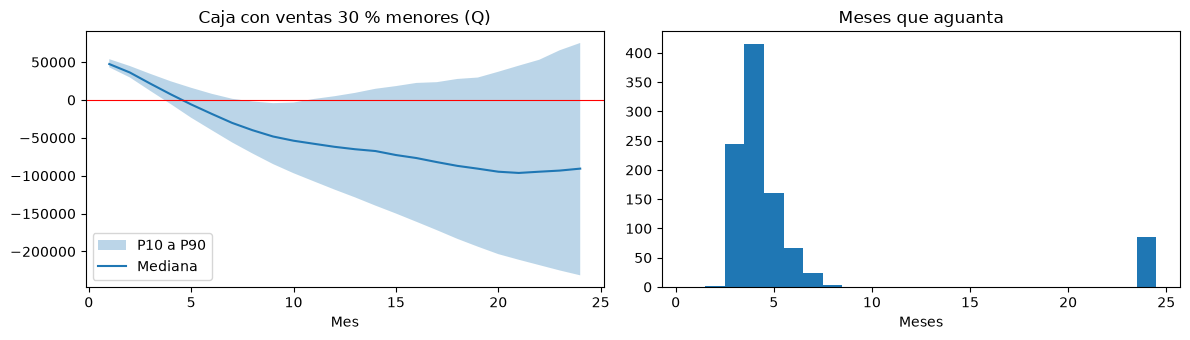

Probabilidad de quedarse sin caja en 24 meses = 0.915


,Meses que aguanta,Caja mínima (Q),Caja final (Q)
Peor (P10),3.0,-231462.0,-231462.0
Probable (P50),4.0,-97823.0,-90618.0
Mejor (P90),7.0,-5460.0,75275.0


In [4]:
baja, caja_baja = run_montecarlo(N, p, cp, qp, tabla, seed=1, level=0.7)

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
abanico(caja_baja, "Caja con ventas 30 % menores (Q)", ejes[0])
ejes[1].hist(baja["months"], bins=np.arange(0.5, p.horizon + 1.5))
ejes[1].set_title("Meses que aguanta")
ejes[1].set_xlabel("Meses")
plt.tight_layout()
plt.show()
print(f"Probabilidad de quedarse sin caja en 24 meses = {1 - baja['survived'].mean():.3f}")
rango(baja)

Con ventas 30 % menores el negocio se queda sin caja en el 91.5 % de los escenarios. Aguanta 3 meses en el escenario peor, 4 en el probable y 7 en el mejor. Solo unos 85 de los 1 000 escenarios llegan al mes 24.

## 5. ¿Cuántos clientes se necesita retener cada mes?

La retención mensual es la fracción de clientes activos que no abandona el negocio en el mes. Se prueban siete niveles de abandono promedio con 500 escenarios cada uno.

In [5]:
filas = []
for churn in [0.02, 0.03, 0.04, 0.06, 0.08, 0.10, 0.12]:
    r, _ = run_montecarlo(500, p, replace(cp, mean_churn=churn), qp, tabla, seed=2)
    filas.append({
        "Retención mensual": 1 - churn,
        "Probabilidad de llegar al mes 24": r["survived"].mean(),
        "Meses que aguanta (mediana)": r["months"].median(),
        "Clientes activos mes 24 (mediana)": r["active_end"].median(),
    })
retencion = pd.DataFrame(filas).set_index("Retención mensual")
retencion["Clientes retenidos por mes (mes 24)"] = retencion["Clientes activos mes 24 (mediana)"] * retencion.index
retencion.round(3)

,Probabilidad de llegar al mes 24,Meses que aguanta (mediana),Clientes activos mes 24 (mediana),Clientes retenidos por mes (mes 24)
Retención mensual,,,,
0.98,0.922,24.0,1008.0,987.84
0.97,0.886,24.0,965.0,936.05
0.96,0.852,24.0,922.0,885.12
0.94,0.800,24.0,836.5,786.31
0.92,0.680,24.0,744.0,684.48
0.90,0.538,24.0,648.5,583.65
0.88,0.380,7.0,556.0,489.28


La probabilidad de llegar al mes 24 crece con la retención. Con la retención base de 92 % es de 68.0 %. Para que el riesgo de quedarse sin caja sea menor a 10 % se necesita retener al menos 98 % de los clientes cada mes, con lo que la probabilidad es de 92.2 %. En el mes 24 eso equivale a retener unos 988 clientes por mes. Con 97 % de retención la probabilidad baja a 88.6 %.

## Conclusión

El modelo integrado entrega rangos en lugar de un solo valor. Con la demanda esperada el riesgo de quedarse sin caja en 24 meses es de 35.0 %, y con ventas 30 % menores sube a 91.5 %. El siguiente notebook compara estrategias para reducir ese riesgo.